# IND320 - Part 4

**André Olesen**

- GitHub repository: https://github.com/Andreolesen/AndreOlesen-IND320
- Streamlit app: https://andreolesen-ind320.streamlit.app/

In this part, exchange rates from Norges Bank are added, the time zones of the four data sources are compared,
and the reservoir filling for one region is forecast with River (SNARIMAX and a lag-based model). The Streamlit
app is refactored with a new structure, Plotly plots, an interactive map, sliding window correlation and a
forecasting page.

## Imports
All imports are here

In [1]:
import io
import json
import os
import time
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from pymongo import MongoClient
from river import forest, linear_model, optim, preprocessing, time_series

## Exchange rates from Norges Bank
Norges Bank has an open API for its statistics (SDMX). The exchange rates are in the dataset `EXR`, and one
series is chosen with a key of four parts separated by dots:

| Part | Value | Meaning |
|---|---|---|
| Frequency | `B` | business days (also `D`, `M`, `A`) |
| Base currency | `EUR+USD` | the currencies, `+` gives several at once |
| Quote currency | `NOK` | the price is given in Norwegian kroner |
| Tenor | `SP` | spot rate |

So `EXR/B.EUR+USD.NOK.SP` is the daily spot rate of EUR and USD in NOK. With `format=csv` the answer is a table
with one row per currency and day. The value is NOK per 1 unit of the currency (for EUR and USD the unit
multiplier is 0, so 1 EUR = OBS_VALUE NOK).

In [2]:
# Norges Bank's open API (SDMX) for exchange rates
NB_URL = "https://data.norges-bank.no/api/data/EXR"


def download_exchange_rates(start, end, currencies=("EUR", "USD"), frequency="B"):
    """Download exchange rates (NOK per 1 unit of currency) from Norges Bank.

    Returns a DataFrame with one row per date and one column per currency.
    """
    key = f"{frequency}.{'+'.join(currencies)}.NOK.SP"
    params = {"format": "csv", "startPeriod": start, "endPeriod": end, "locale": "en"}
    response = requests.get(f"{NB_URL}/{key}", params=params, timeout=60)
    response.raise_for_status()  # stop with a clear error on HTTP 4xx/5xx

    # sep=None lets pandas find the separator itself (the CSV from Norges Bank uses semicolons)
    raw = pd.read_csv(io.StringIO(response.text), sep=None, engine="python")
    # One row per currency and day -> one column per currency
    rates = raw.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates.astype(float)

### Testing the function

In [3]:
# Test: daily rates for the last 12 months (up to today)
today = pd.Timestamp.today().normalize()
rates = download_exchange_rates((today - pd.DateOffset(years=1)).strftime("%Y-%m-%d"), today.strftime("%Y-%m-%d"))
display(rates.tail())
print(f"{len(rates)} days, from {rates.index.min().date()} to {rates.index.max().date()}")
print("Weekdays in the data:", sorted(rates.index.day_name().unique()))  # business days -> no weekends
print("Missing values:", rates.isna().sum().to_dict())

# Simple checks: both currencies are there and the values are in a reasonable range (NOK per EUR/USD)
assert list(rates.columns) == ["EUR", "USD"]
assert rates["EUR"].between(9, 15).all() and rates["USD"].between(8, 14).all()

,EUR,USD
date,,
2026-11-17,10.5755,9.6237
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076


251 days, from 2025-11-24 to 2026-11-23
Weekdays in the data: ['Friday', 'Monday', 'Thursday', 'Tuesday', 'Wednesday']
Missing values: {'EUR': 0, 'USD': 0}


In [4]:
# Test with other settings: monthly averages and only EUR
monthly = download_exchange_rates("2020-01", "2024-12", currencies=("EUR",), frequency="M")
display(monthly.tail())
assert len(monthly) == 60  # 5 years x 12 months

,EUR
date,
2024-08-01,11.7895
2024-09-01,11.7852
2024-10-01,11.7907
2024-11-01,11.7408
2024-12-01,11.7392


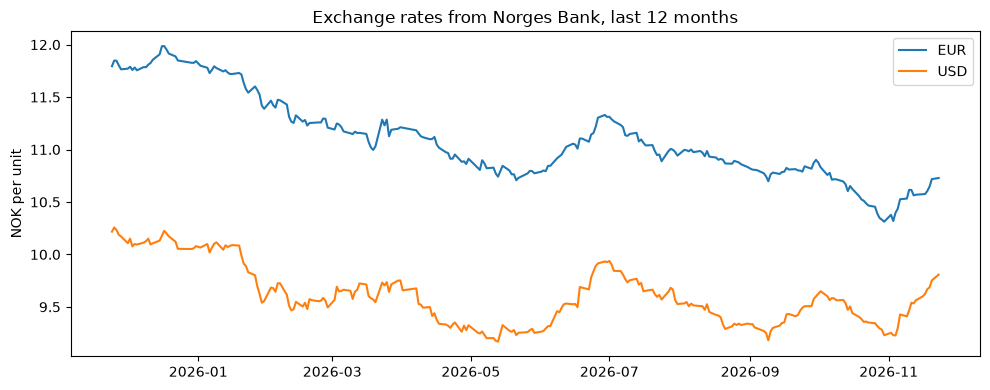

In [5]:
# Plot of the daily rates in the last 12 months
fig, ax = plt.subplots(figsize=(10, 4))
for currency in rates.columns:
    ax.plot(rates.index, rates[currency], label=currency)
ax.set_title("Exchange rates from Norges Bank, last 12 months")
ax.set_ylabel("NOK per unit")
ax.legend()
fig.tight_layout()
plt.show()

## Time zones in the four data sources
The data sources have different time resolutions, and they do not say the time in the same way. Before the
data are combined (for the correlations and the forecast), I check how each source handles time:

- **Magasinstatistikk (NVE):** one value per ISO week, with a date (`dato_Id`) and no clock time.
- **ENTSO-E:** hourly flows. The API takes and returns times in UTC (part 2), and they are stored in MongoDB as
  epoch seconds, which are also UTC.
- **open-meteo (ERA5):** hourly weather. The API returns the time in the zone given by the `timezone`
  parameter (default GMT = UTC); in part 3 I asked for UTC.
- **Norges Bank:** one rate per business day, with a date and no clock time. The rates are mid-rates from the
  interbank market at a given time of day, published at about 16:00 Norwegian time.

The cells below check this in the data.

In [6]:
# 1. Magasinstatistikk: which weekday is dato_Id, and is there a clock time?
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
reservoirs = pd.DataFrame(requests.get(NVE_URL, headers={"Accept": "application/json"}, timeout=60).json())
print("Example of dato_Id:", reservoirs["dato_Id"].iloc[0], "-> a date, no clock time and no time zone")
dates = pd.to_datetime(reservoirs["dato_Id"])
print("Weekdays in dato_Id:", dates.dt.day_name().unique().tolist())
print("Time zone:", dates.dt.tz)

Example of dato_Id: 2020-11-15 -> a date, no clock time and no time zone
Weekdays in dato_Id: ['Sunday']
Time zone: None


In [7]:
# 2. open-meteo: the same day asked for in UTC and in Norwegian time, in winter (UTC+1) and summer (UTC+2)
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
for day, expected_hours in [("2026-01-15", 1), ("2026-07-01", 2)]:
    for zone in ["UTC", "Europe/Oslo"]:
        params = {"latitude": 60.77, "longitude": 9.57, "start_date": day, "end_date": day,
                  "hourly": "temperature_2m", "models": "era5", "timezone": zone}
        answer = requests.get(WEATHER_URL, params=params, timeout=60).json()
        if "hourly" not in answer:  # open-meteo answers with an error message, e.g. when the API limit is reached
            raise RuntimeError(f"open-meteo: {answer.get('reason', answer)}")
        print(f"{day} {zone:12s} first time stamps: {answer['hourly']['time'][:2]}  "
              f"temperature: {answer['hourly']['temperature_2m'][:3]}  "
              f"offset: {answer['utc_offset_seconds'] / 3600:+.0f} h (expected {'+0' if zone == 'UTC' else f'+{expected_hours}'} h)")

2026-01-15 UTC          first time stamps: ['2026-01-15T00:00', '2026-01-15T01:00']  temperature: [-11.6, -11.9, -11.4]  offset: +0 h (expected +0 h)
2026-01-15 Europe/Oslo  first time stamps: ['2026-01-15T00:00', '2026-01-15T01:00']  temperature: [-11.1, -11.6, -11.9]  offset: +1 h (expected +1 h)
2026-07-01 UTC          first time stamps: ['2026-07-01T00:00', '2026-07-01T01:00']  temperature: [10.9, 10.5, 10.4]  offset: +0 h (expected +0 h)
2026-07-01 Europe/Oslo  first time stamps: ['2026-07-01T00:00', '2026-07-01T01:00']  temperature: [11.2, 10.9, 10.5]  offset: +1 h (expected +2 h)


Norway is UTC+1 in winter and UTC+2 in summer, so asking open-meteo for `Europe/Oslo` should shift the hours by +1
in January and +2 in July. January gave +1 as expected, but **July also gave +1**.

My guess is that open-meteo uses the offset that applies *today* (November, winter time) for all dates. To test
this, the cell below asks for Sydney, which has summer time in November: if both dates get +11, the guess is right.
It also checks that pandas converts the same hours correctly.

In [8]:
# 2b. Follow-up: is the offset taken from today's date? Sydney has summer time (UTC+11) now in November
for day, expected_hours in [("2026-01-15", 11), ("2026-07-01", 10)]:
    params = {"latitude": -33.87, "longitude": 151.21, "start_date": day, "end_date": day,
              "hourly": "temperature_2m", "models": "era5", "timezone": "Australia/Sydney"}
    answer = requests.get(WEATHER_URL, params=params, timeout=60).json()
    if "hourly" not in answer:  # open-meteo answers with an error message, e.g. when the API limit is reached
        raise RuntimeError(f"open-meteo: {answer.get('reason', answer)}")
    print(f"Sydney {day}: offset {answer['utc_offset_seconds'] / 3600:+.0f} h (expected +{expected_hours} h)")

# pandas: the same UTC hours converted to Norwegian time
for day in ["2026-01-15", "2026-07-01"]:
    utc_hour = pd.Timestamp(f"{day} 00:00", tz="UTC")
    print(f"pandas {day}: 00:00 UTC = {utc_hour.tz_convert('Europe/Oslo')}")

Sydney 2026-01-15: offset +11 h (expected +11 h)
Sydney 2026-07-01: offset +11 h (expected +10 h)
pandas 2026-01-15: 00:00 UTC = 2026-01-15 01:00:00+01:00
pandas 2026-07-01: 00:00 UTC = 2026-07-01 02:00:00+02:00


**Result:** Sydney got +11 for both dates, so open-meteo uses today's offset for the whole answer, not the offset
on the dates that are asked for. pandas got it right (+1 in January, +2 in July). The solution is therefore to
download in UTC and let pandas convert to Norwegian time.

In [9]:
# 3. ENTSO-E: the flows that part 2 downloaded (cached locally in data/cache/, not on GitHub)
flows_path = os.path.join("..", "data", "cache", "entsoe_flows.pkl")
if os.path.exists(flows_path):
    flows = pd.read_pickle(flows_path)
    # The time is a column in the cached file; as a DatetimeIndex it has .tz and .normalize()
    time_column = pd.DatetimeIndex(flows.index if isinstance(flows.index, pd.DatetimeIndex) else pd.to_datetime(flows["time"]))
    print("First time stamp:", time_column[0], "| time zone:", time_column.tz)
    # Several rows per hour (one per connection and direction), so count the unique hours
    first_day = time_column[time_column.normalize() == time_column[0].normalize()]
    print("Unique time stamps in the first day:", first_day.nunique(), "(96 = some connections report every 15 minutes)")
else:
    print("No local ENTSO-E cache. The API was called with UTC times (e.g. periodStart=202401010000) in part 2.")

First time stamp: 2024-01-01 00:00:00+00:00 | time zone: UTC
Unique time stamps in the first day: 96 (96 = some connections report every 15 minutes)


In [10]:
# 4. Norges Bank: the rates from the first section
print("Index of the exchange rates:", rates.index[:3].tolist(), "| time zone:", rates.index.tz)
print("Weekdays:", sorted(rates.index.day_name().unique()))
# Weekdays without a rate are Norwegian public holidays (e.g. Christmas, Easter, 17 May)
missing = pd.bdate_range(rates.index.min(), rates.index.max()).difference(rates.index)
print("Weekdays without a rate:", [day.strftime("%a %d %b %Y") for day in missing])

Index of the exchange rates: [Timestamp('2025-11-24 00:00:00'), Timestamp('2025-11-25 00:00:00'), Timestamp('2025-11-26 00:00:00')] | time zone: None
Weekdays: ['Friday', 'Monday', 'Thursday', 'Tuesday', 'Wednesday']
Weekdays without a rate: ['Wed 24 Dec 2025', 'Thu 25 Dec 2025', 'Fri 26 Dec 2025', 'Thu 01 Jan 2026', 'Thu 02 Apr 2026', 'Fri 03 Apr 2026', 'Mon 06 Apr 2026', 'Fri 01 May 2026', 'Thu 14 May 2026', 'Mon 25 May 2026']


### Findings
| Source | Resolution | How time is given | Time zone |
|---|---|---|---|
| Magasinstatistikk | week | date of the Sunday that ends the ISO week, no clock time | none (Norwegian calendar date) |
| ENTSO-E | hour (15 min for some connections) | time stamps from the API, stored as epoch seconds | UTC |
| open-meteo | hour | time stamps without zone marker, zone chosen in the request; one fixed offset (today's) for the whole answer | UTC (as requested) |
| Norges Bank | business day | date, no clock time; mid-rates published at ~16:00 Norwegian time; no rates on holidays | none (Norwegian calendar date) |

The two hourly sources are in UTC, while the two others use Norwegian dates. Since Norway is one or two hours ahead
of UTC, the last hours of a UTC day belong to the next Norwegian day.

**Does it matter?** For weekly values hardly: one or two hours is about 1 % of a week. It matters more for daily
values. In my own app, the Cross-border flows page summed the flows per UTC day, so each "day" started at 01:00 or
02:00 Norwegian time. This is now fixed.

**Solution:** all hourly data are downloaded and stored in UTC, and converted to Norwegian time right before they
are aggregated to days or weeks. The weeks end on Sunday, like the weeks in Magasinstatistikk, so all sources line
up. The function below does this.

In [11]:
# Aggregate hourly data (UTC) to the same weeks as Magasinstatistikk: Norwegian time, weeks ending on Sunday
def to_nve_weeks(hourly, how="mean"):
    """Resample an hourly DataFrame/Series with a UTC index to weekly values with the NVE dates (Sunday).

    how: "mean" (e.g. temperature) or "sum" (e.g. precipitation), or a dict {column: "mean"/"sum"}.
    """
    local = hourly.copy()
    if local.index.tz is None:
        local.index = local.index.tz_localize("UTC")
    local.index = local.index.tz_convert("Europe/Oslo").tz_localize(None)  # Norwegian clock time, no zone marker
    weekly = local.resample("W-SUN").agg(how)
    weekly.index.name = "date"
    return weekly


# Test on the exchange rates (daily, Norwegian dates -> same rule, no conversion needed)
weekly_rates = rates.resample("W-SUN").mean()
display(weekly_rates.head(3))
assert (weekly_rates.index.day_name() == "Sunday").all()

,EUR,USD
date,,
2025-11-30,11.81136,10.2132
2025-12-07,11.77100,10.1058
2025-12-14,11.81210,10.1182


## Forecasting the reservoir filling with River
The task is to forecast the filling of one area for the coming months with [River](https://riverml.xyz), a library
where the model learns one observation at a time. I compare two types of models in one function:

- **SNARIMAX**: It forecasts from the filling in the previous weeks and from the yearly
  pattern, and can also use other variables such as the weather. The settings (`p, d, q` and `sp, sd, sq`) decide
  how many earlier weeks and years it looks at, and how the trend and the yearly pattern are removed.
- **Lag model**: a regression (by default a Bayesian linear regression) that uses the filling in the last few weeks
  and the time of year to predict how much the filling changes to the next week. The forecast is made one week at a
  time, using its own prediction as input for the next week.

Both models can also use the weather and the exchange rates. Since the future weather is not known when a forecast
is made, the forecast uses a "normal" year instead (the average of the same week in earlier years). As a benchmark I
use a **naive** forecast: last year's development, starting from today's level.

### Time resolution
The reservoir data from NVE are weekly, and the forecast is for the coming months, so I use one value per week. The
hourly weather is converted to the same weeks. Ten years of history is then about 520 weeks, which is quick to
train. Hourly data would give 168 times more rows without making the target more precise.

In [12]:
# Weekly fill ratio of one area (from the NVE data loaded in the time-zone section)
def fill_series(area_type="EL", area_number=3):
    """Weekly fill ratio (0-1) of one area as a Series with the NVE dates (Sundays) as index."""
    rows = reservoirs[(reservoirs["omrType"] == area_type) & (reservoirs["omrnr"] == area_number)]
    series = rows.assign(date=pd.to_datetime(rows["dato_Id"])).set_index("date")["fyllingsgrad"].sort_index()
    return series.asfreq("W-SUN").interpolate().rename("fill")  # one row per week; a missing week is filled in


fill_no3 = fill_series("EL", 3)
print(f"{len(fill_no3)} weeks, from {fill_no3.index.min().date()} to {fill_no3.index.max().date()}")

1663 weeks, from 1995-01-08 to 2026-11-15


### Weather sample
The feedback on part 3 suggested a larger weather sample per region, since the average of a few locations may
not represent the whole region. Here the weather is averaged over **20 locations** (5 in my first version), and
they are chosen from different ERA5 grid cells: ERA5 has a grid of 0.25°, so two of the random locations from
part 3 that fall in the same cell would get identical values and add nothing. NO3 has 313 different cells
among its 1000 locations, so there are plenty to choose from.

The limit is open-meteo's free API: one location for one year counts as about 26 calls, and the limits are
600 calls per minute, 5000 per hour and 10 000 per day. 20 locations for 13 years (2014-2026) is about
6800 calls, so the download is split per year and each year is saved in `data/cache/` (Git-ignored). If the hourly
limit is reached, the cell stops with a message and continues from the next missing year when it is run again.
2014 is early enough for 10 years of history before the first test cutoff (March 2024).

In [13]:
# Weekly weather for one region from open-meteo (ERA5), averaged over random locations from part 3
WEATHER_AGG = {"temperature_2m": "mean", "precipitation": "sum"}  # weekly mean temperature, weekly precipitation sum
# The 1000 random locations per region from part 3, stored as GeoJSON points (longitude, latitude)
with open(os.path.join("..", "data", "regions", "region_locations.geojson"), encoding="utf-8") as f:
    LOCATIONS = pd.DataFrame([{"region": feature["properties"]["region"],
                               "longitude": feature["geometry"]["coordinates"][0],
                               "latitude": feature["geometry"]["coordinates"][1]} for feature in json.load(f)["features"]])
ERA5_GRID = 0.25  # degrees; two locations in the same grid cell get identical values


def era5_locations(region, n_locations=20, seed=42):
    """n random locations in a region, at most one per ERA5 grid cell, so every location adds information."""
    points = LOCATIONS[LOCATIONS["region"] == region]
    cells = points.assign(cell_lat=(points["latitude"] / ERA5_GRID).round(),
                          cell_lon=(points["longitude"] / ERA5_GRID).round())
    cells = cells.drop_duplicates(["cell_lat", "cell_lon"])
    return cells.sample(min(n_locations, len(cells)), random_state=seed)


def download_hourly_year(locations, year, variables=tuple(WEATHER_AGG)):
    """Hourly weather for one year, averaged over the locations (UTC index). One request for all locations."""
    last_date = pd.Timestamp.today() - pd.Timedelta(days=7)  # ERA5 is a few days behind
    end = min(pd.Timestamp(f"{year}-12-31"), last_date)
    params = {
        "latitude": ",".join(f"{lat:.4f}" for lat in locations["latitude"]),
        "longitude": ",".join(f"{lon:.4f}" for lon in locations["longitude"]),
        "start_date": f"{year}-01-01", "end_date": end.strftime("%Y-%m-%d"),
        "hourly": ",".join(variables), "models": "era5", "timezone": "UTC",
    }
    for attempt in range(3):
        response = requests.get(WEATHER_URL, params=params, timeout=300)
        if response.status_code != 429:  # 429 = too many requests: wait a minute and try again
            break
        time.sleep(65)
    if response.status_code == 429:
        try:
            reason = response.json().get("reason", "")  # e.g. "Hourly API request limit exceeded"
        except ValueError:
            reason = ""
        raise RuntimeError(f"open-meteo's API limit is reached at year {year} ({reason}). "
                           "The years before are saved in data/cache/; run the cell again later.")
    response.raise_for_status()
    answer = response.json()
    answer = answer if isinstance(answer, list) else [answer]  # one location gives a dict
    hourly = pd.concat([pd.DataFrame(item["hourly"]) for item in answer])
    hourly["time"] = pd.to_datetime(hourly["time"], utc=True)
    return hourly.groupby("time")[list(variables)].mean()  # mean over the locations


def download_weekly_weather(region="NO3", start_year=2014, end_year=2026, n_locations=20, seed=42):
    """Weekly temperature (°C) and precipitation (mm) for a region, averaged over n locations (one per ERA5 cell).

    Downloaded year by year in UTC and saved in data/cache/ per year, so a stopped download can continue later.
    The hourly values are then aggregated to the NVE weeks.
    """
    locations = era5_locations(region, n_locations, seed)
    hourly_frames = []
    for year in range(start_year, end_year + 1):
        path = os.path.join("..", "data", "cache", f"weather_hourly_{region}_{year}_{n_locations}.pkl")
        if os.path.exists(path):
            hourly_frames.append(pd.read_pickle(path))
            continue
        hourly = download_hourly_year(locations, year)
        hourly.to_pickle(path)
        hourly_frames.append(hourly)
        print(f"{year} downloaded", end=" | ")
    hourly = pd.concat(hourly_frames)
    return to_nve_weeks(hourly, WEATHER_AGG).iloc[1:-1]  # drop the first and last week, which are not complete


weather_no3 = download_weekly_weather("NO3")
display(weather_no3.tail(3))

,temperature_2m,precipitation
date,,
2026-10-25,7.389349,8.545
2026-11-01,7.707708,33.665
2026-11-08,5.646280,17.470


In [14]:
# Put the target and the chosen exogenous sources together in one weekly table
def build_dataset(area_type="EL", area_number=3, sources=("weather",), start_year=2014, end_year=2026, n_locations=20):
    """Weekly DataFrame with the fill ratio ("fill") of one area and the exogenous columns of the chosen sources.

    sources: any of "weather" (temperature_2m, precipitation; only for the price areas NO1-NO5) and
    "rates" (EUR, USD from Norges Bank). An empty tuple gives the fill ratio alone.
    n_locations: number of weather locations (one per ERA5 grid cell).
    """
    data = fill_series(area_type, area_number).to_frame()
    if "weather" in sources:
        if area_type != "EL":
            raise ValueError("Weather locations exist only for the price areas (EL)")
        data = data.join(download_weekly_weather(f"NO{area_number}", start_year, end_year, n_locations))
    if "rates" in sources:
        rates = download_exchange_rates(f"{start_year}-01-01", f"{end_year}-12-31")
        data = data.join(rates.resample("W-SUN").mean())
    return data.loc[str(start_year):].dropna()


dataset = build_dataset("EL", 3, sources=("weather", "rates"))
display(dataset.tail(3))
print(f"{len(dataset)} weeks, {dataset.index.min().date()} to {dataset.index.max().date()}")

,fill,temperature_2m,precipitation,EUR,USD
date,,,,,
2026-10-25,0.717647,7.389349,8.545,10.5093,9.37124
2026-11-01,0.720149,7.707708,33.665,10.3668,9.29372
2026-11-08,0.718705,5.646280,17.470,10.4111,9.28732


670 weeks, 2014-01-12 to 2026-11-08


In [15]:
# Save the table locally (git-ignored), so the forecasts can be tested outside the notebook too
dataset.to_pickle(os.path.join("..", "data", "cache", "weather_dataset_NO3.pkl"))


In [16]:
# The forecasting function
WEEKS_PER_YEAR = 52


def exog_features(date, row, exog_columns):
    """Exogenous variables of one step as a dict (River's input format)."""
    return {column: float(row[column]) for column in exog_columns}


def season_position(date, period):
    """Position in the year: the ISO week for weekly data (period 52), the month for monthly data (period 12)."""
    return date.isocalendar().week if period == WEEKS_PER_YEAR else date.month


def lag_features(fills, i, n_lags, date, row, exog_columns, period=WEEKS_PER_YEAR):
    """Input of the lag-based model for step i: the last n_lags fill ratios, the change in the same step last
    year, the time of year and the exogenous variables."""
    position = season_position(date, period)
    x = {f"lag{k}": fills[i - k] for k in range(1, n_lags + 1)}  # lag1 = last step
    x["change_last_year"] = fills[i - period] - fills[i - period - 1]  # same week (month) one year ago
    x["sin_season"] = np.sin(2 * np.pi * position / period)
    x["cos_season"] = np.cos(2 * np.pi * position / period)
    x.update(exog_features(date, row, exog_columns))
    return x


def exog_for_horizon(data, history, future_index, exog_columns, future_exog="normal", period=WEEKS_PER_YEAR):
    """Exogenous values for the forecast steps.

    future_exog="normal": the mean of the same week (month) in the training history, a "normal" year. This is
                          what a real forecast of the coming months has to do, since the future weather is unknown.
    future_exog="known":  the real values when they are in data (only possible when testing on the past).
    """
    positions = lambda index: [season_position(d, period) for d in index]
    normal = history[exog_columns].groupby(positions(history.index)).mean()
    fallback = normal.reindex(positions(future_index)).ffill().bfill()
    fallback.index = future_index
    if future_exog == "known":
        return data.reindex(future_index)[exog_columns].fillna(fallback)
    return fallback


def forecast_filling(data, model="snarimax", history_weeks=520, horizon_weeks=26, cutoff=None,
                     p=2, d=0, q=1, sp=1, sd=1, sq=0, lr=0.01, n_lags=4, learner=None,
                     future_exog="normal", period=WEEKS_PER_YEAR):
    """Forecast the fill ratio with River.

    data:           DataFrame from build_dataset(): column "fill" plus the exogenous columns to use.
    model:          "snarimax", "lags" or "naive" (last year's development from today's level).
    history_weeks:  how many steps (weeks, or months for monthly data) before the cutoff are used for training.
    horizon_weeks:  how many steps ahead to forecast.
    cutoff:         last date of the training data. Default: the last date in data (a real forecast).
                    An earlier date gives a test forecast that can be compared with what happened.
    p, d, q, sp, sd, sq: SNARIMAX orders (seasonal period m = period).
    lr:             learning rate of the SGD regression inside SNARIMAX.
    n_lags:         number of past steps in the lag-based model.
    learner:        a function that returns a fresh River regressor for the lag-based model
                    (default: standard scaler + Bayesian linear regression).
    future_exog:    "normal" (a normal year, as in a real forecast) or "known" (the real future values).
    period:         steps per year: 52 for weekly data, 12 for monthly data.
    Returns (forecast Series, seconds used).
    """
    cutoff = data.index[-1] if cutoff is None else pd.Timestamp(cutoff)
    history = data.loc[:cutoff].iloc[-history_weeks:]
    frequency = "W-SUN" if period == WEEKS_PER_YEAR else "ME"
    future_index = pd.date_range(cutoff, periods=horizon_weeks + 1, freq=frequency)[1:]
    exog_columns = [column for column in data.columns if column != "fill"]
    future = exog_for_horizon(data, history, future_index, exog_columns, future_exog, period)
    fills = history["fill"].tolist()
    start = time.perf_counter()

    if model == "naive":
        # Last year's change from the same point, added to today's level (positions in the regular series)
        full = data["fill"].to_numpy()
        c = data.index.get_loc(history.index[-1])
        values = [fills[-1] + full[c + h - period] - full[c - period] for h in range(1, horizon_weeks + 1)]

    elif model == "snarimax":
        regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(optimizer=optim.SGD(lr), intercept_lr=lr)
        arima = time_series.SNARIMAX(p=p, d=d, q=q, m=period, sp=sp, sd=sd, sq=sq, regressor=regressor)
        for date, row in history.iterrows():
            arima.learn_one(row["fill"], exog_features(date, row, exog_columns))
        xs = [exog_features(date, row, exog_columns) for date, row in future.iterrows()]
        values = arima.forecast(horizon=horizon_weeks, xs=xs)

    elif model == "lags":
        # Bayesian linear regression has a closed-form update, so one pass over the history fits it exactly
        # (an SGD regression needed many passes and still did worse than the naive forecast)
        regressor = learner() if learner else (preprocessing.StandardScaler() | linear_model.BayesianLinearRegression())
        first = max(n_lags, period) + 1  # the features need a year of history
        for i in range(first, len(history)):
            x = lag_features(fills, i, n_lags, history.index[i], history.iloc[i], exog_columns, period)
            regressor.learn_one(x, fills[i] - fills[i - 1])  # target: the change since last step
        values = []
        for date, row in future.iterrows():
            x = lag_features(fills, len(fills), n_lags, date, row, exog_columns, period)
            fills.append(fills[-1] + regressor.predict_one(x))  # dynamic: the prediction becomes the newest lag
            values.append(fills[-1])
    else:
        raise ValueError(f"Unknown model: {model}")

    seconds = time.perf_counter() - start
    forecast = pd.Series(np.clip(np.asarray(values, dtype=float), 0, 1), index=future_index, name="forecast")
    return forecast, seconds

### Testing the function
A forecast is tested by choosing a cutoff inside the data, forecasting the next 26 weeks and comparing with what
really happened (backtesting). The error is the mean absolute error (MAE) in percentage points (pp) of fill
ratio. The cutoffs are every 13 weeks from January 2021 to March 2026 (22 forecasts), so all seasons are included and
one lucky or unlucky season does not decide. The training window slides along with the cutoff. Each setting is
also timed.

**Future weather.** When the forecast is tested on the past, the real weather in the forecast weeks is known.
Using it would make the test too optimistic: in a real forecast of the coming months the future weather is
unknown. So the tests use a *normal year* for the exogenous variables in the forecast weeks (the mean of the same
week in the training data), just like the app does. One test below shows how much the real future weather would
have flattered the result. (A classmate's notebook pointed out this problem, which my first version had.)

The weather data start in 2014, so for the earliest cutoffs the history is shorter than 10 years.

In [17]:
# Test one setting from many cutoffs; returns the mean error (pp), how often it beats the naive forecast, and the time
# Every 13 weeks from January 2021 to May 2026 (the last cutoff still has 26 weeks of data after it)
CUTOFFS = pd.date_range("2021-01-03", "2026-05-31", freq="13W-SUN")
print(len(CUTOFFS), "cutoffs, from", CUTOFFS[0].date(), "to", CUTOFFS[-1].date())


def errors_per_cutoff(data, cutoffs=CUTOFFS, **settings):
    """Mean absolute error (pp) over the horizon from each cutoff, and the mean time per forecast."""
    errors, seconds = [], []
    for cutoff in cutoffs:
        forecast, used = forecast_filling(data, cutoff=cutoff, **settings)
        actual = data["fill"].reindex(forecast.index)
        errors.append((forecast - actual).abs().mean() * 100)
        seconds.append(used)
    return np.array(errors), float(np.mean(seconds))


naive_errors, _ = errors_per_cutoff(dataset[["fill"]], model="naive")


def test_forecast(data, cutoffs=CUTOFFS, **settings):
    """Mean error (pp), share of cutoffs where the setting beats the naive forecast, and seconds per forecast."""
    errors, seconds = errors_per_cutoff(data, cutoffs, **settings)
    return {"mae_pp": errors.mean(), "beats_naive": (errors < naive_errors).mean(), "seconds": seconds}


# A first run of each model with the default settings and weather as exogenous input (normal future weather)
for model in ["naive", "snarimax", "lags"]:
    print(model, {k: round(v, 3) for k, v in test_forecast(dataset[["fill", "temperature_2m", "precipitation"]], model=model).items()})

22 cutoffs, from 2021-01-03 to 2026-03-29
naive {'mae_pp': np.float64(10.398), 'beats_naive': np.float64(0.0), 'seconds': 0.0}
snarimax {'mae_pp': np.float64(8.158), 'beats_naive': np.float64(0.636), 'seconds': 0.012}
lags {'mae_pp': np.float64(9.304), 'beats_naive': np.float64(0.545), 'seconds': 0.02}


In [18]:
# Compare settings: model, exogenous sources, future weather, length of history, SNARIMAX orders, lags and learner
WEATHER = ["temperature_2m", "precipitation"]
settings = [
    {"name": "naive", "model": "naive", "columns": []},
    {"name": "snarimax", "model": "snarimax", "columns": []},
    {"name": "snarimax + weather", "model": "snarimax", "columns": WEATHER},
    {"name": "snarimax + weather, real future weather", "model": "snarimax", "columns": WEATHER, "future_exog": "known"},
    {"name": "snarimax + rates", "model": "snarimax", "columns": ["EUR", "USD"]},
    {"name": "snarimax, d=1 sd=0", "model": "snarimax", "columns": [], "d": 1, "sd": 0},
    {"name": "snarimax, p=1 d=1 q=1 sq=1", "model": "snarimax", "columns": [], "p": 1, "d": 1, "q": 1, "sq": 1},
    {"name": "snarimax, 5 years", "model": "snarimax", "columns": [], "history_weeks": 260},
    {"name": "lags", "model": "lags", "columns": []},
    {"name": "lags, n_lags=2", "model": "lags", "columns": [], "n_lags": 2},
    {"name": "lags + weather, n_lags=2", "model": "lags", "columns": WEATHER, "n_lags": 2},
    {"name": "lags + weather, n_lags=2, real future weather", "model": "lags", "columns": WEATHER, "n_lags": 2,
     "future_exog": "known"},
    {"name": "lags + rates, n_lags=2", "model": "lags", "columns": ["EUR", "USD"], "n_lags": 2},
    {"name": "lags, n_lags=13", "model": "lags", "columns": [], "n_lags": 13},
    {"name": "lags, n_lags=2, 5 years", "model": "lags", "columns": [], "n_lags": 2, "history_weeks": 260},
    {"name": "lags, n_lags=2, random forest", "model": "lags", "columns": [], "n_lags": 2,
     "learner": lambda: forest.ARFRegressor(n_models=10, seed=42)},
]
results = []
for setting in settings:
    setting = dict(setting)
    name, columns = setting.pop("name"), setting.pop("columns")
    result = test_forecast(dataset[["fill"] + columns], **setting)
    results.append({"setting": name, **result})
results = pd.DataFrame(results).sort_values("mae_pp").set_index("setting")
display(results.round(3))

,mae_pp,beats_naive,seconds
setting,,,
"lags + weather, n_lags=2, real future weather",7.416,0.636,0.018
snarimax,7.919,0.636,0.011
"snarimax + weather, real future weather",8.039,0.682,0.012
"lags, n_lags=2, random forest",8.075,0.682,0.231
snarimax + weather,8.158,0.636,0.012
"lags + rates, n_lags=2",8.384,0.545,0.018
"lags, n_lags=13",8.630,0.636,0.016
"lags, n_lags=2",8.667,0.545,0.013
lags,8.789,0.591,0.015


### 5 or 20 weather locations?
The same two settings are tested with weather averaged over 5 and over 20 locations (both one per ERA5 cell),
to see if the larger sample gives better forecasts.

In [19]:
# Larger weather sample (feedback from part 3): the same settings with weather from 5 and from 20 locations
dataset_5 = build_dataset("EL", 3, sources=("weather",), n_locations=5)
rows = []
for name, setting in [("lags + weather, n_lags=2", {"model": "lags", "n_lags": 2}),
                      ("snarimax + weather", {"model": "snarimax"})]:
    errors_5, _ = errors_per_cutoff(dataset_5[["fill"] + WEATHER], **setting)
    errors_20, _ = errors_per_cutoff(dataset[["fill"] + WEATHER], **setting)
    rows.append({"setting": name, "mae_pp, 5 locations": errors_5.mean(), "mae_pp, 20 locations": errors_20.mean(),
                 "20 better at": f"{(errors_20 < errors_5).sum()} of {len(CUTOFFS)} cutoffs"})
display(pd.DataFrame(rows).set_index("setting").round(2))

# How different are the two weather samples? (weekly values, same weeks)
both = dataset_5[WEATHER].join(dataset[WEATHER], lsuffix="_5", rsuffix="_20", how="inner")
for column in WEATHER:
    difference = (both[f"{column}_5"] - both[f"{column}_20"]).abs().mean()
    print(f"{column}: mean absolute difference between 5 and 20 locations = {difference:.2f}")

,"mae_pp, 5 locations","mae_pp, 20 locations",20 better at
setting,,,
"lags + weather, n_lags=2",9.05,9.05,10 of 22 cutoffs
snarimax + weather,8.40,8.16,15 of 22 cutoffs


temperature_2m: mean absolute difference between 5 and 20 locations = 1.81
precipitation: mean absolute difference between 5 and 20 locations = 5.14


### Time resolution: weeks or months?
The same data as monthly values: the fill ratio at the end of each month, the mean temperature, the precipitation
summed over the month and the mean exchange rates. The models then have a season of 12 months, a history of 120
months (10 years) and a horizon of 6 months, forecast from the end of the month of each weekly cutoff. The error
is measured at the month ends, so it is not exactly the same as the weekly error, but both cover about half a year.

In [20]:
# Monthly data: fill ratio at the end of the month, weather and exchange rates per month
monthly = dataset.resample("ME").agg({"fill": "last", "temperature_2m": "mean", "precipitation": "sum",
                                      "EUR": "mean", "USD": "mean"}).iloc[1:-1]  # drop the incomplete first and last month
monthly_cutoffs = sorted({(cutoff + pd.offsets.MonthEnd(0)) for cutoff in CUTOFFS if cutoff + pd.offsets.MonthEnd(6) <= monthly.index[-1]})
monthly_settings = {"history_weeks": 120, "horizon_weeks": 6, "period": 12, "cutoffs": monthly_cutoffs}

rows = []
for name, setting, columns in [("naive", {"model": "naive"}, []),
                               ("snarimax", {"model": "snarimax"}, []),
                               ("lags, n_lags=2", {"model": "lags", "n_lags": 2}, []),
                               ("lags + weather, n_lags=2", {"model": "lags", "n_lags": 2}, WEATHER)]:
    weekly_errors, weekly_seconds = errors_per_cutoff(dataset[["fill"] + columns], **setting)
    monthly_errors, monthly_seconds = errors_per_cutoff(monthly[["fill"] + columns], **monthly_settings, **setting)
    rows.append({"setting": name, "mae_pp, weekly": weekly_errors.mean(), "mae_pp, monthly": monthly_errors.mean(),
                 "seconds, weekly": weekly_seconds, "seconds, monthly": monthly_seconds})
display(pd.DataFrame(rows).set_index("setting").round(3))

,"mae_pp, weekly","mae_pp, monthly","seconds, weekly","seconds, monthly"
setting,,,,
naive,10.398,10.808,0.000,0.000
snarimax,7.919,8.803,0.010,0.003
"lags, n_lags=2",8.667,8.260,0.014,0.003
"lags + weather, n_lags=2",9.047,8.473,0.019,0.004


### Findings
**How I tested.** Every setting was run from 22 cutoffs (every 13 weeks from January 2021 to March 2026) with a
horizon of 26 weeks. The error is the mean absolute error over the horizon, averaged over the cutoffs, and the
table also shows how often a setting beats the naive forecast (last year's development from today's level), the
benchmark a useful model must beat. The exogenous variables get a normal year in the forecast weeks, as in a real
forecast. My first version used only six cutoffs and the real future weather; after seeing a classmate's
backtest I changed both, and the conclusions changed.

**Results.**
- **SNARIMAX without exogenous variables is the best:** 7.9 pp, against 10.4 pp for the naive forecast. It beats
  the naive forecast at 64 % of the cutoffs, so the errors still vary a lot from season to season.
- **The lag-based model** with Bayesian linear regression is a little behind: 8.7 pp with 2 lags and 8.6 with 13.
  The random forest (`ARFRegressor`) is close (8.1 pp), but about 15 times slower.
- **The real future weather flatters the test.** With the real weather in the forecast weeks, the lag-based model
  with weather gets 7.4 pp (the best in the table), but with a normal year it gets 9.0, worse than without weather
  (8.7). So my first conclusion, that weather helps, came from knowing the future weather. When the weather has to
  be guessed, temperature and precipitation make both models slightly worse (SNARIMAX 7.9 → 8.2).
- **Exchange rates** made SNARIMAX much worse (10.5) and the lag model slightly better (8.4). There is no physical link from the exchange rate to the water in the reservoirs. An indirect link is possible through power prices and exports (a weak krone makes Norwegian power cheaper in Europe), but it is too weak to help: the results go in different directions for the two models, so I do not use the exchange rates.
- **Seasonal differencing is essential:** without it (`d=1, sd=0`) SNARIMAX got 14.6 pp. The order (1,1,1)(1,1,1)
  was also clearly worse here (11.3).
- **History length:** 10 years was better than 5 for both models (11.6 and 11.4 pp with 5 years).
- **Weather sample (5 or 20 locations):** the weekly weather differs clearly between the samples (on average
  1.8 °C and 5 mm per week), but the forecasts hardly change: the lag model is the same (9.05 pp) and SNARIMAX is
  a little better with 20 (8.16 against 8.40, better at 15 of 22 cutoffs). The app stores 5 locations for its long
  weather series, since 20 would cost four times as many API calls for almost no gain.
- **Time resolution:** weekly SNARIMAX (7.9 pp) is better than monthly (8.8). The lag model is a little better
  monthly (8.3 against 8.7), but still behind weekly SNARIMAX. Weekly data also match the resolution of
  Magasinstatistikk, so nothing is lost, and every forecast takes less than 0.05 seconds, so the weekly resolution
  does not take an unreasonable amount of time.

**A lesson about River.** My first lag-based model used River's ordinary `LinearRegression`, which learns with
stochastic gradient descent, one observation at a time. With only about 500 weeks of training data, several
passes over the data and a tuned learning rate, it was still worse than the naive forecast (about 20 pp).
`BayesianLinearRegression` updates the exact solution with every observation instead, and fixed the problem at
once. Online learning is a strength when the data keep streaming in, but with a small, fixed history the
closed-form model is both faster and better.

**Default for the app:** SNARIMAX with orders (2,0,1)(1,1,0) and a season of 52 weeks, 10 years of history, no
exogenous variables and a horizon of 26 weeks. The exogenous variables and the lag-based model can still be
chosen in the app.

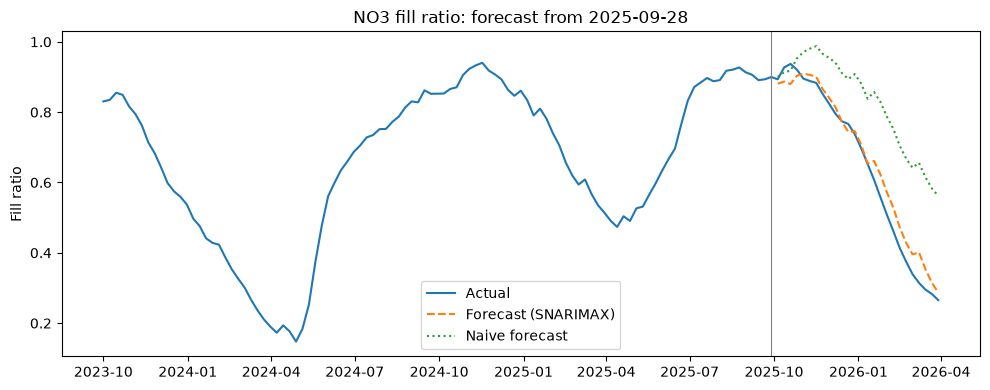

In [21]:
# Plot of the best setting and the naive forecast from one cutoff, against what happened
cutoff = CUTOFFS[-3]
best, _ = forecast_filling(dataset[["fill"]], cutoff=cutoff, model="snarimax")
naive, _ = forecast_filling(dataset[["fill"]], cutoff=cutoff, model="naive")

fig, ax = plt.subplots(figsize=(10, 4))
shown = dataset["fill"].loc[cutoff - pd.Timedelta(weeks=104):best.index[-1]]
ax.plot(shown.index, shown, label="Actual")
ax.plot(best.index, best, label="Forecast (SNARIMAX)", linestyle="--")
ax.plot(naive.index, naive, label="Naive forecast", linestyle=":")
ax.axvline(cutoff, color="grey", linewidth=0.8)
ax.set_title(f"NO3 fill ratio: forecast from {cutoff.date()}")
ax.set_ylabel("Fill ratio")
ax.legend()
fig.tight_layout()
plt.show()

## Structure of the Streamlit app

Before the app was refactored, the new structure was sketched:

![Sketch of the app structure](images/app_sketch.png)

- **Menu bar at the top, grouped by type of task.** The pages are grouped into *Explore the data*, *Patterns and
  anomalies* and *Forecast* (`st.navigation` with sections), with the Overview page first. Each group has its own
  colour, shown above the page title.
- **Global choices on the Overview page.** Area type, area (click on the map) and period are chosen once and kept in
  `st.session_state`, so the other pages use the same choices. Each page shows the choices it uses in a line under
  the title, with a button that opens a popover where they can be changed (the same session state keys, so the
  Overview page and the other pages follow). This was added after testing: going back to the Overview page every
  time was cumbersome. Local choices (weather property, model parameters, currencies,
  …) are made on the page itself.
- **Fewer, larger pages.** The old LineChartColumn page and the reservoir plot are merged into *Reservoir data*.
  New pages: *Exchange rates*, *Weather vs reservoir* (sliding window correlation) and *Reservoir forecast*.
- **Look.** A fixed theme ("Fjord") in `.streamlit/config.toml`, and all plots in Plotly with a shared template in
  the same colours. The map is a Plotly choropleth from the GeoJSON files, coloured by the chosen variable.

## Weather for the Streamlit app (stored in MongoDB)
In the first version of the app, the weather was downloaded from open-meteo while the user waited: a forecast
with 10 years of weather took a few minutes the first time for each area, and the map coloured by weather had to
download all areas. A real app would not do that. The data would be prepared beforehand and stored, so the web
page only reads finished numbers. This is the same pattern as the ENTSO-E data in part 2 (notebook → database →
app).

So the weekly weather for all nine areas in Magasinstatistikk (NO1–NO5, VASS1–VASS3 and Norway) is downloaded here,
aggregated to the NVE weeks and stored in MongoDB (collection `weather_weekly`). The app only reads it from there. The page with outliers still
downloads hourly weather directly, since it needs hours for one area and a short period.

- **Locations:** 5 per area, one per ERA5 grid cell, chosen exactly like `area_locations()` in the app. The
  forecast tests above showed that 5 or 20 locations give almost the same forecast error.
- **API budget:** 9 areas × 13 years (2014–2026) × 5 locations × about 26 calls ≈ 15 000 calls, more than the
  daily limit of 10 000 (and the hourly limit of 5000). Each year is saved in `data/cache/` (the current year is reused for a week), so when
  a limit is reached the cell stops with a message and continues where it stopped when it is run again.
- **Up to date until the day the cell is run.** The app does not download newer weeks itself, so it never waits for
  open-meteo; the forecast uses a normal year for weeks after the last stored week.
- **In a real app**, this cell would be a scheduled job (for example once a week) that adds the new weeks.

In [22]:
# Weekly weather for every area in Magasinstatistikk, the same way the app chooses locations and weeks
APP_VARIABLES = {"temperature_2m": "mean", "precipitation": "sum", "rain": "sum", "snowfall": "sum",
                 "relative_humidity_2m": "mean", "wind_speed_10m": "mean", "cloud_cover": "mean"}
APP_AREAS = [("EL", n) for n in range(1, 6)] + [("VASS", n) for n in range(1, 4)] + [("NO", 0)]
VASS_REGIONS = {1: ["RØ", "RS"], 2: ["RV"], 3: ["RM", "RN"]}  # same as in data_utils.py
APP_LOCATIONS = 5     # N_LIGHT_LOCATIONS in the app
FIRST_APP_YEAR = 2014


def app_locations(area_type, number, n_locations=APP_LOCATIONS, seed=42):
    """The same random locations as area_locations() in data_utils.py: one per ERA5 cell, in the area's regions."""
    regions = [f"NO{number}"] if area_type == "EL" else VASS_REGIONS[number] if area_type == "VASS" \
        else [f"NO{n}" for n in range(1, 6)]
    points = LOCATIONS[LOCATIONS["region"].isin(regions)]
    cells = points.assign(cell_lat=(points["latitude"] / ERA5_GRID).round(),
                          cell_lon=(points["longitude"] / ERA5_GRID).round()).drop_duplicates(["cell_lat", "cell_lon"])
    return cells.sample(min(n_locations, len(cells)), random_state=seed)


def app_weekly_weather(area_type, number):
    """Weekly weather (NVE weeks) from 2014 until now. Every year is cached in data/cache/, so a new run only uses
    API calls for what is missing. The current year is downloaded again when its file is more than a week old."""
    locations = app_locations(area_type, number)
    this_year = pd.Timestamp.today().year
    frames = []
    for year in range(FIRST_APP_YEAR, this_year + 1):
        path = os.path.join("..", "data", "cache", f"app_weather_{area_type}{number}_{year}.pkl")
        fresh = os.path.exists(path) and (year < this_year or time.time() - os.path.getmtime(path) < 7 * 24 * 3600)
        if fresh:
            frames.append(pd.read_pickle(path))
            continue
        hourly = download_hourly_year(locations, year, variables=tuple(APP_VARIABLES))
        hourly.to_pickle(path)
        frames.append(hourly)
        print(f"{area_type}{number} {year}", end=" | ")
    hourly = pd.concat(frames)
    weekly = to_nve_weeks(hourly, APP_VARIABLES)
    hours = to_nve_weeks(hourly[["temperature_2m"]].notna(), "sum")["temperature_2m"]
    return weekly[hours >= 0.9 * 168]  # drop weeks with less than 90 % of the hours (the ends)


# Read the MongoDB URI from the same secrets file as the app (Git-ignored), and connect
with open(os.path.join("..", ".streamlit", "secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)
mongo = MongoClient(secrets["mongo"]["uri"])
weather_collection = mongo["ind320"]["weather_weekly"]

# One area at a time: download (or read the cache), then replace that area's documents in MongoDB
for area_type, number in APP_AREAS:
    try:
        weekly = app_weekly_weather(area_type, number)
    except RuntimeError as error:  # an API limit is reached: stop here, the next run continues
        print(f"\nStopped at {area_type}{number}: {error}")
        break
    records = weekly.reset_index().assign(area_type=area_type, area_number=number).to_dict("records")
    weather_collection.delete_many({"area_type": area_type, "area_number": number})
    weather_collection.insert_many(records)
    print(f"\n{area_type}{number}: {len(records)} weeks stored, {weekly.index.min().date()} to {weekly.index.max().date()}")

# Index on the fields the app filters on, so reading one area is fast
weather_collection.create_index([("area_type", 1), ("area_number", 1), ("date", 1)])


EL1: 670 weeks stored, 2014-01-12 to 2026-11-08

EL2: 670 weeks stored, 2014-01-12 to 2026-11-08

EL3: 670 weeks stored, 2014-01-12 to 2026-11-08

EL4: 670 weeks stored, 2014-01-12 to 2026-11-08

EL5: 670 weeks stored, 2014-01-12 to 2026-11-08

VASS1: 670 weeks stored, 2014-01-12 to 2026-11-08

VASS2: 670 weeks stored, 2014-01-12 to 2026-11-08

VASS3: 670 weeks stored, 2014-01-12 to 2026-11-08

NO0: 670 weeks stored, 2014-01-12 to 2026-11-08


'area_type_1_area_number_1_date_1'

In [23]:
# Check what is stored in MongoDB: number of weeks and the first and last week per area
pipeline = [{"$group": {"_id": {"type": "$area_type", "number": "$area_number"}, "weeks": {"$sum": 1},
                        "first": {"$min": "$date"}, "last": {"$max": "$date"}}},
            {"$sort": {"_id.type": 1, "_id.number": 1}}]
stored = pd.DataFrame([{"area": f"{r['_id']['type']}{r['_id']['number']}", "weeks": r["weeks"],
                        "first week": r["first"].date(), "last week": r["last"].date()}
                       for r in weather_collection.aggregate(pipeline)])
display(stored)
assert len(stored) == len(APP_AREAS), "Not all areas are stored yet: run the cell above again later"

,area,weeks,first week,last week
0,EL1,670,2014-01-12,2026-11-08
1,EL2,670,2014-01-12,2026-11-08
2,EL3,670,2014-01-12,2026-11-08
3,EL4,670,2014-01-12,2026-11-08
4,EL5,670,2014-01-12,2026-11-08
5,NO0,670,2014-01-12,2026-11-08
6,VASS1,670,2014-01-12,2026-11-08
7,VASS2,670,2014-01-12,2026-11-08
8,VASS3,670,2014-01-12,2026-11-08


## AI usage

I used Claude (Opus 5.5) in this part as well. Claude explained methods I had not used before (SNARIMAX in River, sliding window
correlation), suggested how the forecast could be tested fairly and helped writing code and text. The decisions were mine, made after discussing the options with claude. 


## Log

The exchange rates were downloaded from Norges Bank, which was straightforward. The time zones took more thought.
Two of the sources give dates without a time of day, while the hourly data are in UTC. To make sure everything
ended up in the right week, I downloaded all hourly data in UTC and converted to Norwegian time myself. This
mattered, since open-meteo's own conversion ignored summer time.

The forecast was the part where I learned the most. My first tests used the real weather in the weeks being
forecast, and the weather looked like it helped a lot. After talking with a classmate, I realised that this is not
fair, since nobody knows the future weather. With a normal year instead, the simpler model without weather was the
best. A test can give good numbers and still be unrealistic, and this changed the default model in the app.

I went through the feedback on part 3 before finishing this part. The teaching assistant suggested a larger weather
sample, so I increased it from 5 to 20 locations per area, but for the forecast 5 and 20 gave almost the same
result. Because of the API limits, the app uses 20 locations only where the hourly weather itself is studied, and
for the same reason I did not add the slider for the number of locations that my peer reviewer suggested. From the
peer review I added the water areas to the weather pages, replaced the CSV file with GeoJSON, gave the outlier
tables readable column names and updated the README.

The app was planned before it was built. I used Claude to discuss the structure, made a sketch and grouped the
pages by type of task, with the map on the front page. Going back to the front page every time was tiring, as the
peer review also pointed out, so the area and period can now be changed from every page.

The biggest change in my thinking was about how a real website should work. At first the app downloaded the weather
while the user waited. Now the weekly weather for all areas is prepared in the notebook and stored in MongoDB, and
the app only reads it. The download took trial and error with the API limits and had to be spread over two days.
As bonus task I chose waiting time: everything possible is cached, progress bars and spinners show ongoing work, and
the app says clearly when an API limit is reached.

Playing with the sliding window correlation showed that much of the link between weather and reservoirs is the
shared yearly cycle. Snowfall is negatively correlated with the filling in the same week, but positively about
20-26 weeks later, when the snow melts. Precipitation hardly correlates over the whole period, but strongly in
autumn and winter. For predictions, the snow that has already fallen could be useful, while future weather adds
little.